# Interpretable Traffic Signal Control: Group 87

**Budhdi Prakash Sharma, 2025AG05273**  
**Sumeet Kulkarni, 2025AG05175**

An end-to-end CPU demonstration of DQN, DRQ, DRSQ and DRHQ. Upload this notebook to Google Colab and select **Runtime > Run all**. A GPU is unnecessary. All source code is included below.

Paper: [Ault, Hanna and Sharon, AAMAS 2020](https://arxiv.org/abs/1912.11023).

**Scope:** a synthetic FIFO queue simulator and a restricted polynomial policy. This does not reproduce the original SUMO/UDOT experiment or its 19.4% result. The measured metric is queue delay accumulated inside the horizon per vehicle arrival, not complete trip delay.

The saved outputs are a preparation-environment CPU run. Run the notebook yourselves to establish contributor proof. Use the equal-participation log to record actual work. Code uses ordinary names and comments that explain decisions and formulas.

## 1. Working folder and dependencies

Colab already provides the scientific packages. This cell checks imports. Source files go into a dedicated folder, so the notebook can also run from a fresh downloaded copy.

In [1]:
from pathlib import Path
import os, sys, json, time, importlib.util
for package in ('numpy', 'pandas', 'matplotlib', 'PIL'):
    if importlib.util.find_spec(package) is None:
        raise ImportError(f"Missing {package}. Install the packages in requirements.txt first.")
WORKDIR = Path.cwd() if Path.cwd().name == 'drl_group87' else Path.cwd() / 'drl_group87'
WORKDIR.mkdir(exist_ok=True)
os.chdir(WORKDIR)
for folder in ('traffic_control', 'tests', 'results'):
    Path(folder).mkdir(exist_ok=True)
if str(WORKDIR) not in sys.path:
    sys.path.insert(0, str(WORKDIR))
print('Python:', sys.version.split()[0])
print('Working folder:', WORKDIR)
import numpy as np, pandas as pd
from datetime import datetime, timezone
print('Started (UTC):', datetime.now(timezone.utc).isoformat())
print('NumPy:', np.__version__, 'pandas:', pd.__version__)


Python: 3.12.14
Working folder: /workspace/scratch/981aa7d81c9f/build/notebook_test_final_v2/drl_group87
Started (UTC): 2026-10-10T08:35:53.658006+00:00
NumPy: 2.3.5 pandas: 2.2.3


## 2. Settings and units

The full study uses 50 episodes for each algorithm and each of three training seeds. Each episode lasts 1,200 seconds. You can inspect all settings here.

In [2]:
%%writefile traffic_control/config.py
"""Shared settings. Times are in seconds and rates are vehicles/second."""
from dataclasses import dataclass, asdict

DIRECTIONS = ('North', 'South', 'East', 'West')
ACTION_NAMES = ('North / South', 'East / West')
MOVEMENTS = ((0, 1), (2, 3))
FEATURE_NAMES = ('queued', 'approaching', 'total_wait', 'mean_wait', 'queue_per_lane', 'speed')
SCALES = (30., 5., 1800., 120., 30., 15.)

@dataclass
class Settings:
    horizon: int = 1200
    decision_seconds: int = 10
    yellow_seconds: int = 2
    all_red_seconds: int = 1
    service_per_second: int = 1
    episodes: int = 50
    batch_size: int = 32
    replay_capacity: int = 12000
    target_interval: int = 100
    warmup: int = 128
    gamma: float = 0.95
    learning_rate: float = 0.001
    policy_learning_rate: float = 0.003
    epsilon_start: float = 0.30
    epsilon_end: float = 0.03
    policy_updates: int = 2
    hidden: int = 32

    def validate(self):
        if self.horizon < self.decision_seconds or self.horizon % self.decision_seconds:
            raise ValueError('horizon must be a positive multiple of decision_seconds')
        if self.yellow_seconds < 0 or self.all_red_seconds < 0:
            raise ValueError('clearance durations cannot be negative')
        if self.yellow_seconds + self.all_red_seconds >= self.decision_seconds:
            raise ValueError('each decision must leave some green time')
        if self.service_per_second < 1 or self.episodes < 1 or self.batch_size < 1:
            raise ValueError('service, episodes and batch_size must be positive')
        if self.replay_capacity < self.batch_size or self.warmup < self.batch_size:
            raise ValueError('replay capacity and warmup must cover a minibatch')
        if not 0 <= self.gamma < 1 or self.target_interval < 1:
            raise ValueError('invalid discount or target interval')
        return self

    def to_dict(self):
        return asdict(self)


Writing traffic_control/config.py


## 3. Traffic environment

Each direction has one FIFO queue. North/South and East/West are the only valid actions. Switching incurs 2 seconds yellow and 1 second all-red, with no service during clearance. Arrivals continue during clearance. The next scheduled one-second arrivals form an idealized approach detector.

In [3]:
%%writefile traffic_control/environment.py
"""A small FIFO queue simulator with enforced signal clearance.

This is a teaching environment, not a SUMO replacement. Opposing through
movements share green. Arrivals enter stopped queues immediately. No turning,
acceleration, spillback, pedestrians or sensor error is modeled.
"""
from collections import deque
import numpy as np
from .config import Settings, MOVEMENTS, SCALES

SCENARIOS = ('balanced', 'tidal')


def demand_rates(scenario, horizon):
    if scenario not in SCENARIOS:
        raise ValueError(f'Unknown demand scenario: {scenario}')
    rates = np.full((horizon, 4), 0.30)
    if scenario == 'tidal':
        midpoint = horizon // 2
        rates[:midpoint] = [0.54, 0.48, 0.12, 0.16]
        rates[midpoint:] = [0.12, 0.16, 0.54, 0.48]
    return rates


def make_arrivals(scenario, horizon, seed):
    # Generate demand before control starts, so every controller sees the same traffic.
    return np.random.default_rng(seed).poisson(demand_rates(scenario, horizon))


class Intersection:
    observation_size = 32
    action_count = 2

    def __init__(self, settings=None):
        self.settings = (settings or Settings()).validate()

    def reset(self, scenario='balanced', seed=0, arrivals=None):
        self.arrivals = make_arrivals(scenario, self.settings.horizon, seed) if arrivals is None else np.asarray(arrivals)
        if self.arrivals.shape != (self.settings.horizon, 4):
            raise ValueError('arrivals must have shape (horizon, 4)')
        if np.any(self.arrivals < 0) or np.any(self.arrivals != self.arrivals.astype(int)):
            raise ValueError('arrival counts must be nonnegative integers')
        self.queues = [deque() for _ in range(4)]
        self.time = 0
        self.phase = 0
        self.green_age = 0
        self.delay = 0
        self.arrived = 0
        self.departed = 0
        self.switches = 0
        self.departure_waits = []
        self.history = []
        return self.observe()

    def raw_features(self):
        values = np.zeros((4, 6), dtype=float)
        for lane, queue in enumerate(self.queues):
            count = len(queue)
            total_wait = sum(self.time - entry for entry in queue)
            # One second of scheduled arrivals is a synthetic approach detector.
            approaching = self.arrivals[self.time, lane] if self.time < len(self.arrivals) else 0
            values[lane] = [count, approaching, total_wait,
                            total_wait / count if count else 0, count,
                            12.0 if approaching else 0.0]
        return values

    def observe(self):
        traffic = (self.raw_features() / np.asarray(SCALES)).ravel()
        flags = np.zeros((2, 4), dtype=float)
        flags[:, 0] = 1.0  # full clearance when changing direction
        flags[self.phase] = [0., 0., 0., 1.]  # no clearance for the current green
        return np.concatenate([traffic, flags.ravel()])

    def step(self, action):
        if action not in (0, 1):
            raise ValueError('action must be 0 or 1')
        if self.time >= self.settings.horizon:
            raise RuntimeError('episode has ended; call reset before step')
        switch = int(action != self.phase)
        if switch:
            self.switches += 1
            self.green_age = 0
        clearance = switch * (self.settings.yellow_seconds + self.settings.all_red_seconds)
        start_delay = self.delay
        self.phase = int(action)
        for tick in range(self.settings.decision_seconds):
            for lane, count in enumerate(self.arrivals[self.time]):
                for _ in range(int(count)):
                    self.queues[lane].append(self.time)
                self.arrived += int(count)
            if tick < clearance:
                signal = 'yellow' if tick < self.settings.yellow_seconds else 'all_red'
                served = ()
            else:
                signal = 'green'
                served = MOVEMENTS[action]
                self.green_age += 1
            for lane in served:
                for _ in range(min(len(self.queues[lane]), self.settings.service_per_second)):
                    entry = self.queues[lane].popleft()
                    self.departure_waits.append(self.time - entry)
                    self.departed += 1
            counts = [len(q) for q in self.queues]
            # Every remaining vehicle waits through this one-second interval.
            self.delay += sum(counts)
            self.history.append({'second': self.time, 'phase': self.phase,
                                 'signal': signal, **{f'q{i}': n for i, n in enumerate(counts)},
                                 'arrived': self.arrived, 'departed': self.departed,
                                 'delay_vehicle_seconds': self.delay})
            self.time += 1
        done = self.time >= self.settings.horizon
        reward = -(self.delay - start_delay) / 100.0
        return self.observe(), reward, done, self.metrics()

    def metrics(self):
        pending = sum(len(q) for q in self.queues)
        waits = np.asarray(self.departure_waits)
        return {'delay_per_arrival_s': self.delay / max(self.arrived, 1),
                'delay_vehicle_seconds': self.delay, 'arrived': self.arrived,
                'departed': self.departed, 'pending': pending,
                'throughput_fraction': self.departed / max(self.arrived, 1),
                'completed_mean_wait_s': float(waits.mean()) if len(waits) else 0.,
                'completed_p95_wait_s': float(np.percentile(waits, 95)) if len(waits) else 0.,
                'switches': self.switches,
                'conservation_ok': self.arrived == self.departed + pending}


Writing traffic_control/environment.py


## 4. Teacher and regulatable policy

The teacher has two hidden layers and trains with Huber loss. The deployed actor uses signed weights, positive clearance factors and powers between 1 and 2. Its score derivative has a fixed sign for each feature at a fixed checkpoint. Analytic gradients are explicit and checked against finite differences. The local score is w*x**p, adapted from the paper.

In [4]:
%%writefile traffic_control/networks.py
"""Small NumPy networks with explicit gradients, suitable for CPU notebooks."""
import copy
import numpy as np
from .config import MOVEMENTS


def softmax(values):
    shifted = values - np.max(values, axis=1, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=1, keepdims=True)


def sigmoid(x):
    return 1. / (1. + np.exp(-np.clip(x, -30., 30.)))


class Adam:
    def __init__(self, parameters, rate):
        self.rate = rate
        self.m = {key: np.zeros_like(value) for key, value in parameters.items()}
        self.v = {key: np.zeros_like(value) for key, value in parameters.items()}
        self.steps = 0

    def update(self, parameters, gradients):
        self.steps += 1
        norm = np.sqrt(sum(np.sum(g * g) for g in gradients.values()))
        scale = min(1., 10. / max(norm, 1e-12))
        for key, parameter in parameters.items():
            grad = gradients[key] * scale
            if not np.all(np.isfinite(grad)):
                raise FloatingPointError(f'Nonfinite gradient in {key}')
            self.m[key] = .9 * self.m[key] + .1 * grad
            self.v[key] = .999 * self.v[key] + .001 * grad * grad
            first = self.m[key] / (1. - .9 ** self.steps)
            second = self.v[key] / (1. - .999 ** self.steps)
            parameter -= self.rate * first / (np.sqrt(second) + 1e-8)


class QNetwork:
    def __init__(self, seed=0, hidden=32, rate=.001):
        rng = np.random.default_rng(seed)
        self.parameters = {}
        for layer, (inputs, outputs) in enumerate(((32, hidden), (hidden, hidden), (hidden, 2))):
            self.parameters[f'w{layer}'] = rng.normal(0., np.sqrt(2. / inputs), (inputs, outputs))
            self.parameters[f'b{layer}'] = np.zeros(outputs)
        self.optimizer = Adam(self.parameters, rate)

    def forward(self, state, cache=False):
        x = np.atleast_2d(state)
        z0 = x @ self.parameters['w0'] + self.parameters['b0']
        h0 = np.maximum(z0, .01 * z0)
        z1 = h0 @ self.parameters['w1'] + self.parameters['b1']
        h1 = np.maximum(z1, .01 * z1)
        result = h1 @ self.parameters['w2'] + self.parameters['b2']
        return (result, (x, z0, h0, z1, h1)) if cache else result

    def gradients(self, state, actions, targets):
        scores, (x, z0, h0, z1, h1) = self.forward(state, cache=True)
        row = np.arange(len(x))
        error = scores[row, actions] - targets
        absolute = np.abs(error)
        loss = np.mean(np.where(absolute <= 1., .5 * error ** 2, absolute - .5))
        upstream = np.zeros_like(scores)
        upstream[row, actions] = np.clip(error, -1., 1.) / len(x)
        gradients = {'w2': h1.T @ upstream, 'b2': upstream.sum(axis=0)}
        dh1 = (upstream @ self.parameters['w2'].T) * np.where(z1 > 0, 1., .01)
        gradients.update(w1=h0.T @ dh1, b1=dh1.sum(axis=0))
        dh0 = (dh1 @ self.parameters['w1'].T) * np.where(z0 > 0, 1., .01)
        gradients.update(w0=x.T @ dh0, b0=dh0.sum(axis=0))
        return float(loss), gradients

    def train(self, state, actions, targets):
        loss, gradients = self.gradients(state, actions, targets)
        self.optimizer.update(self.parameters, gradients)
        return loss

    def clone(self):
        return copy.deepcopy(self)

    def sync(self, other):
        for key in self.parameters:
            self.parameters[key][:] = other.parameters[key]


class RegulatablePolicy:
    """Monotonic precedence scores with learnable weights and powers.

    G_a = c_a(flag) * sum_{served lane,feature} w * x**p.
    We allow signed weights. At a fixed checkpoint each partial derivative
    has a fixed sign. p is bounded between 1 and 2, including at x = 0.
    This is a restricted polynomial family inspired by Equation 1. The
    paper puts weights inside powers. Here they multiply outside powers.
    Clearance exponents are redundant for one-hot flags and are fixed at 1.
    """
    def __init__(self, rate=.003):
        self.parameters = {'weight': np.ones((2, 2, 6)),
                           'power_raw': np.full((2, 2, 6), -4.),
                           'clear_raw': np.full((2, 4), 2.)}
        self.parameters['clear_raw'][:, 0] = -.8
        self.optimizer = Adam(self.parameters, rate)

    def forward(self, state, cache=False):
        state = np.atleast_2d(state)
        features = state[:, :24].reshape(-1, 4, 6)
        x = np.stack([features[:, list(lanes), :] for lanes in MOVEMENTS], axis=1)
        flags = state[:, 24:].reshape(-1, 2, 4)
        power_sigmoid = sigmoid(self.parameters['power_raw'])
        power = 1. + power_sigmoid
        raised = x ** power[None]
        terms = raised * self.parameters['weight'][None]
        base = terms.sum(axis=(2, 3))
        clear_sigmoid = sigmoid(self.parameters['clear_raw'])
        factors = .1 + .9 * clear_sigmoid
        clearance = np.sum(flags * factors[None], axis=2)
        scores = base * clearance
        details = (x, flags, power_sigmoid, raised, base, clear_sigmoid, clearance)
        return (scores, details) if cache else scores

    def loss_and_gradients(self, states, teacher_scores, variant, actions=None, targets=None):
        scores, (x, flags, ps, raised, base, cs, clearance) = self.forward(states, cache=True)
        batch = len(states)
        if variant == 'DRQ':
            # Algorithm 1 lines 19-21 use the TD target for the sampled action.
            error = scores[np.arange(batch), actions] - targets
            loss = np.mean(error ** 2)
            upstream = np.zeros_like(scores)
            upstream[np.arange(batch), actions] = 2. * error / batch
        else:
            probabilities = softmax(scores)
            if variant == 'DRSQ':
                target = softmax(teacher_scores)
            elif variant == 'DRHQ':
                target = np.eye(2)[np.argmax(teacher_scores, axis=1)]
            else:
                raise ValueError('variant must be DRQ, DRSQ or DRHQ')
            loss = -np.mean(np.sum(target * np.log(np.maximum(probabilities, 1e-15)), axis=1))
            upstream = (probabilities - target) / batch
        multiplier = upstream * clearance
        weight_grad = np.sum(multiplier[:, :, None, None] * raised, axis=0)
        # x**p log(x) tends to zero at x=0. Avoid evaluating log(0).
        log_x = np.log(np.maximum(x, 1e-15))
        power_grad = np.sum(multiplier[:, :, None, None] * raised * log_x
                            * self.parameters['weight'][None], axis=0) * ps * (1. - ps)
        clear_grad = np.sum(upstream[:, :, None] * base[:, :, None] * flags, axis=0)
        clear_grad *= .9 * cs * (1. - cs)
        return float(loss), {'weight': weight_grad, 'power_raw': power_grad, 'clear_raw': clear_grad}

    def train(self, states, teacher_scores, variant, actions=None, targets=None):
        loss, gradients = self.loss_and_gradients(states, teacher_scores, variant, actions, targets)
        self.optimizer.update(self.parameters, gradients)
        return loss

    def explain(self, state):
        scores, (x, flags, ps, raised, base, cs, clearance) = self.forward(state, cache=True)
        contributions = (raised * self.parameters['weight'][None] * clearance[:, :, None, None])[0]
        return {'scores': scores[0].tolist(), 'action': int(np.argmax(scores[0])),
                'clearance_factors': clearance[0].tolist(),
                'contributions': contributions.tolist(),
                'powers': (1. + ps).tolist(), 'weights': self.parameters['weight'].tolist()}

    def input_derivatives(self, state):
        scores, (x, flags, ps, raised, base, cs, clearance) = self.forward(state, cache=True)
        p = 1. + ps
        return self.parameters['weight'][None] * p[None] * x ** (p[None] - 1.) * clearance[:, :, None, None]


Writing traffic_control/networks.py


## 5. Online learning

DQN acts through Q. The regulatable variants act through G from the start while their own Q teacher learns off-policy. DRQ fits a TD target, DRSQ fits soft preferences and DRHQ fits the teacher's best action. Replay and target synchronization stabilize the teacher.

In [5]:
%%writefile traffic_control/training.py
"""Online DQN teacher training and the three regulatable actuators."""
import numpy as np
from .environment import Intersection, SCENARIOS
from .networks import QNetwork, RegulatablePolicy

ALGORITHMS = ('DQN', 'DRQ', 'DRSQ', 'DRHQ')


class Replay:
    def __init__(self, capacity):
        self.capacity = capacity
        self.size = 0
        self.position = 0
        self.states = np.zeros((capacity, 32))
        self.next_states = np.zeros((capacity, 32))
        self.actions = np.zeros(capacity, dtype=int)
        self.rewards = np.zeros(capacity)
        self.done = np.zeros(capacity)

    def append(self, state, action, reward, next_state, done):
        i = self.position
        self.states[i], self.next_states[i] = state, next_state
        self.actions[i], self.rewards[i], self.done[i] = action, reward, done
        self.position = (i + 1) % self.capacity
        self.size = min(self.capacity, self.size + 1)

    def sample(self, batch_size, rng):
        indices = rng.choice(self.size, batch_size, replace=False)
        return (self.states[indices], self.actions[indices], self.rewards[indices],
                self.next_states[indices], self.done[indices])


def td_targets(rewards, done, next_scores, gamma):
    return rewards + gamma * (1. - done) * np.max(next_scores, axis=1)


def train_agent(algorithm, seed, settings, verbose=True):
    if algorithm not in ALGORITHMS:
        raise ValueError(f'Unknown algorithm: {algorithm}')
    settings.validate()
    rng = np.random.default_rng(seed)
    teacher = QNetwork(seed, settings.hidden, settings.learning_rate)
    target = teacher.clone()
    actor = None if algorithm == 'DQN' else RegulatablePolicy(settings.policy_learning_rate)
    replay = Replay(settings.replay_capacity)
    env = Intersection(settings)
    log = []
    updates = 0
    steps = 0
    for episode in range(settings.episodes):
        scenario = SCENARIOS[episode % len(SCENARIOS)]
        # Evaluation uses a separate seed range and never tunes parameters.
        demand_seed = 10000 + seed * 1000 + episode
        state = env.reset(scenario, demand_seed)
        fraction = episode / max(settings.episodes - 1, 1)
        epsilon = settings.epsilon_start + fraction * (settings.epsilon_end - settings.epsilon_start)
        q_losses, g_losses, agreements = [], [], []
        done = False
        while not done:
            actuator = teacher if actor is None else actor
            action = int(rng.integers(2)) if rng.random() < epsilon else int(np.argmax(actuator.forward(state)[0]))
            next_state, reward, done, info = env.step(action)
            replay.append(state, action, reward, next_state, done)
            state = next_state
            steps += 1
            if replay.size < settings.warmup:
                continue
            batch = replay.sample(settings.batch_size, rng)
            s, a, r, ns, terminal = batch
            y = td_targets(r, terminal, target.forward(ns), settings.gamma)
            q_losses.append(teacher.train(s, a, y))
            updates += 1
            if updates % settings.target_interval == 0:
                target.sync(teacher)
            if actor is not None:
                for _ in range(settings.policy_updates):
                    s, a, r, ns, terminal = replay.sample(settings.batch_size, rng)
                    y = td_targets(r, terminal, target.forward(ns), settings.gamma)
                    q_scores = teacher.forward(s)
                    g_losses.append(actor.train(s, q_scores, algorithm, a, y))
                    agreements.append(np.mean(np.argmax(actor.forward(s), axis=1) == np.argmax(q_scores, axis=1)))
        log.append({'algorithm': algorithm, 'train_seed': seed, 'episode': episode + 1,
                    'scenario': scenario, 'epsilon': epsilon, 'q_loss': float(np.mean(q_losses)) if q_losses else 0.,
                    'g_loss': float(np.mean(g_losses)) if g_losses else 0.,
                    'replay_agreement': float(np.mean(agreements)) if agreements else 1.,
                    **info})
        if verbose and (episode + 1) % 10 == 0:
            print(f'{algorithm:4s} seed={seed} episode={episode+1:3d} delay={info["delay_per_arrival_s"]:6.2f}s', flush=True)
    return {'teacher': teacher, 'actor': actor, 'log': log, 'seed': seed,
            'algorithm': algorithm, 'updates': updates, 'steps': steps}


def save_agent(agent, path):
    payload = {f'q_{k}': v for k, v in agent['teacher'].parameters.items()}
    if agent['actor'] is not None:
        payload.update({f'g_{k}': v for k, v in agent['actor'].parameters.items()})
    np.savez_compressed(path, **payload)


def load_agent(path, algorithm, settings):
    teacher = QNetwork(hidden=settings.hidden)
    actor = None if algorithm == 'DQN' else RegulatablePolicy()
    with np.load(path) as values:
        for key in teacher.parameters:
            teacher.parameters[key][:] = values[f'q_{key}']
        if actor is not None:
            for key in actor.parameters:
                actor.parameters[key][:] = values[f'g_{key}']
    return {'teacher': teacher, 'actor': actor, 'algorithm': algorithm}


Writing traffic_control/training.py


## 6. Frozen evaluation

Evaluation never updates parameters. Controllers share the same pre-generated arrivals. Paired intervals resample held-out demand streams after averaging training seeds. They quantify demand variation conditional on these trained models.

In [6]:
%%writefile traffic_control/evaluation.py
"""Frozen-policy evaluation, paired comparisons and interpretable examples."""
import numpy as np
import pandas as pd
from .environment import Intersection, SCENARIOS

BASELINES = ('Fixed', 'Actuated', 'QueueGreedy')


def baseline_action(name, env):
    queues = np.array([len(q) for q in env.queues])
    totals = np.array([queues[:2].sum(), queues[2:].sum()])
    if name == 'Fixed':
        return (env.time // 30) % 2
    if name == 'QueueGreedy':
        # Staying wins ties, so an empty intersection does not flicker.
        return env.phase if totals[0] == totals[1] else int(np.argmax(totals))
    if name == 'Actuated':
        other = 1 - env.phase
        if env.green_age >= 60 or (totals[env.phase] == 0 and totals[other] > 0):
            return other
        return env.phase
    raise ValueError(f'Unknown baseline: {name}')


def rollout(controller, scenario, demand_seed, settings, agent=None):
    env = Intersection(settings)
    state = env.reset(scenario, demand_seed)
    done = False
    decisions = []
    while not done:
        if agent is None:
            action = baseline_action(controller, env)
            scores = [float('nan'), float('nan')]
        else:
            actuator = agent['teacher'] if agent['actor'] is None else agent['actor']
            scores = actuator.forward(state)[0]
            action = int(np.argmax(scores))
        decisions.append({'second': env.time, 'action': action,
                          'score_NS': float(scores[0]), 'score_EW': float(scores[1])})
        state, reward, done, metrics = env.step(action)
    return metrics, pd.DataFrame(env.history), pd.DataFrame(decisions)


def evaluate(agents, settings, demand_seeds=range(90000, 90010)):
    rows = []
    training_seeds = sorted(set(seed for _, seed in agents))
    for scenario in SCENARIOS:
        for demand_seed in demand_seeds:
            for baseline in BASELINES:
                metrics, _, _ = rollout(baseline, scenario, demand_seed, settings)
                rows.append({'scenario': scenario, 'algorithm': baseline, 'train_seed': -1,
                             'demand_seed': demand_seed, **metrics})
            for (algorithm, seed), agent in agents.items():
                metrics, _, _ = rollout(algorithm, scenario, demand_seed, settings, agent)
                rows.append({'scenario': scenario, 'algorithm': algorithm, 'train_seed': seed,
                             'demand_seed': demand_seed, **metrics})
    return pd.DataFrame(rows)


def paired_summary(results, bootstrap_seed=482):
    rng = np.random.default_rng(bootstrap_seed)
    rows = []
    # Average training seeds within each held-out demand. Bootstrap demand seeds,
    # not every row: outcomes on a shared arrival stream are paired observations.
    grouped = results.groupby(['scenario', 'algorithm', 'demand_seed'])['delay_per_arrival_s'].mean()
    for scenario in SCENARIOS:
        baseline = grouped.loc[(scenario, 'Actuated')]
        for algorithm in results.algorithm.unique():
            current = grouped.loc[(scenario, algorithm)].reindex(baseline.index)
            pairs = np.column_stack([baseline.values, current.values])
            indices = rng.integers(0, len(pairs), size=(2000, len(pairs)))
            resampled = pairs[indices].mean(axis=1)
            improvements = 100. * (resampled[:, 0] - resampled[:, 1]) / resampled[:, 0]
            estimate = 100. * (baseline.mean() - current.mean()) / baseline.mean()
            lower, upper = np.percentile(improvements, [2.5, 97.5])
            rows.append({'scenario': scenario, 'algorithm': algorithm,
                         'delay_s': float(current.mean()), 'improvement_pct': float(estimate),
                         'paired_ci_low_pct': float(lower), 'paired_ci_high_pct': float(upper),
                         'demand_runs': len(pairs)})
    return pd.DataFrame(rows)


def decision_example(actor, scenario, settings, seed=90000, at_second=300):
    env = Intersection(settings)
    state = env.reset(scenario, seed)
    for _ in range(at_second // settings.decision_seconds):
        action = int(np.argmax(actor.forward(state)[0]))
        state, _, done, _ = env.step(action)
    explanation = actor.explain(state)
    explanation.update(scenario=scenario, demand_seed=seed, second=env.time,
                       raw_features=env.raw_features().tolist(),
                       normalized_state=state.tolist(), current_phase=env.phase)
    return explanation


def monotonicity_check(actor, seed=733, count=100):
    rng = np.random.default_rng(seed)
    states = rng.uniform(0., 2., (count, 32))
    states[:, 24:] = np.tile([0, 0, 0, 1, 1, 0, 0, 0], (count, 1))
    derivatives = actor.input_derivatives(states)
    expected = np.sign(actor.parameters['weight'])
    return {'checked_derivatives': int(derivatives.size),
            'sign_violations': int(np.sum(derivatives * expected[None] < -1e-10)),
            'finite': bool(np.all(np.isfinite(derivatives)))}


Writing traffic_control/evaluation.py


## 6A. Extra evidence checks

This module checks empty traffic, bursts, demand reversal and overload without updating the learned parameters. It also saves a compact proof summary and an optional contributor run record.

In [7]:
%%writefile traffic_control/proof.py
"""Small diagnostic runs for the presentation's proof of work."""
from pathlib import Path
import json
import platform
import sys
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from .config import Settings
from .environment import Intersection
from .evaluation import baseline_action
from .training import load_agent


def parameter_copy(agent):
    return {name: {key: value.copy() for key, value in model.parameters.items()}
            for name, model in agent.items()
            if name in ('teacher', 'actor') and model is not None}


def unchanged_parameters(agent, before):
    return all(np.array_equal(value, agent[name].parameters[key])
               for name, parameters in before.items() for key, value in parameters.items())


def diagnostic_arrivals(horizon):
    empty = np.zeros((horizon, 4), dtype=int)
    one_sided = empty.copy()
    one_sided[0, 2] = 30
    reversal = empty.copy()
    reversal[0, :2] = 20
    reversal[horizon // 2, 2:] = 20
    # Deliberately above service capacity. A growing queue is expected here.
    overloaded = np.full((horizon, 4), 2, dtype=int)
    return {'empty': empty, 'one_sided_burst': one_sided,
            'burst_reversal': reversal, 'overloaded': overloaded}


def run_diagnostics(actor_agent, settings=None):
    cfg = settings or Settings(horizon=200)
    before = parameter_copy(actor_agent)
    rows = []
    for case, arrivals in diagnostic_arrivals(cfg.horizon).items():
        for controller in ('Fixed', 'Actuated', 'QueueGreedy', 'DRHQ'):
            env = Intersection(cfg)
            state = env.reset(arrivals=arrivals)
            done = False
            while not done:
                if controller == 'DRHQ':
                    scores = actor_agent['actor'].forward(state)[0]
                    assert np.all(np.isfinite(scores)), f'{case}: nonfinite scores'
                    action = int(np.argmax(scores))
                else:
                    action = baseline_action(controller, env)
                state, _, done, metrics = env.step(action)
            assert metrics['conservation_ok'], f'{case}: vehicle accounting failed'
            assert all(np.isfinite(v) for v in metrics.values()), f'{case}: nonfinite metrics'
            pending_wait = sum(env.time - entry for queue in env.queues for entry in queue)
            assert np.isclose(sum(env.departure_waits) + pending_wait, env.delay)
            if case == 'empty':
                assert metrics['delay_vehicle_seconds'] == 0 and metrics['pending'] == 0
            rows.append({'case': case, 'algorithm': controller, **metrics})
    frozen = unchanged_parameters(actor_agent, before)
    assert frozen, 'Evaluation changed learned parameters'
    return pd.DataFrame(rows), frozen


def save_proof(folder='results', contributor='', contribution=''):
    folder = Path(folder)
    manifest = json.loads((folder / 'manifest.json').read_text())
    cfg = Settings(**manifest['settings'])
    seed = manifest['demonstration_seed']
    agent = load_agent(folder / 'models' / f'DRHQ_{seed}.npz', 'DRHQ', cfg)
    diagnostics, frozen = run_diagnostics(agent)
    diagnostics.to_csv(folder / 'diagnostics.csv', index=False)
    evaluation = pd.read_csv(folder / 'evaluation.csv')
    tests = (folder / 'tests.txt').read_text() if (folder / 'tests.txt').exists() else ''
    checks = {
        'training_episodes': manifest['training_episodes_total'],
        'frozen_evaluation_rollouts': len(evaluation),
        'diagnostic_rollouts': len(diagnostics),
        'conservation_all_rollouts': bool((evaluation.arrived == evaluation.departed + evaluation.pending).all()),
        'diagnostic_parameters_unchanged': bool(frozen),
        'tests_reported_ok': '\nOK' in tests,
        'metric': 'waiting inside horizon / all arrivals, seconds',
        'scope': manifest['scope'],
    }
    (folder / 'proof_summary.json').write_text(json.dumps(checks, indent=2))
    record = {
        'contributor_name': contributor.strip(),
        'actual_contribution': contribution.strip(),
        'status': 'recorded' if contributor.strip() and contribution.strip() else 'pending personal details',
        'utc_time': datetime.now(timezone.utc).isoformat(),
        'python': sys.version.split()[0], 'numpy': np.__version__,
        'platform': platform.platform(), 'checks': checks,
        'result_hashes': manifest['files_sha256'],
    }
    (folder / 'contributor_run.json').write_text(json.dumps(record, indent=2))
    return diagnostics, checks, record


Writing traffic_control/proof.py


## 7. Plotting measured evidence

Charts read the saved CSVs. The queue animation shows executed signal choices, including clearance gaps. Nothing in these plots is a typed performance claim.

In [8]:
%%writefile traffic_control/visuals.py
"""Plots made from saved CSVs and model explanations."""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from .config import DIRECTIONS, FEATURE_NAMES

COLORS={'Fixed':'#94a3b8','Actuated':'#e79836','QueueGreedy':'#758344',
        'DQN':'#506cc8','DRQ':'#ae657d','DRSQ':'#55a0b4','DRHQ':'#008c78'}


def save_figure(fig,path):
    fig.savefig(path,dpi=140,bbox_inches='tight',facecolor='white')
    plt.close(fig)


def make_figures(folder):
    folder=Path(folder)
    charts=folder/'figures'
    charts.mkdir(exist_ok=True)
    plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
    summary=pd.read_csv(folder/'summary.csv')
    training=pd.read_csv(folder/'training.csv')
    for scenario in ('balanced','tidal'):
        group=summary[summary.scenario==scenario]
        fig,ax=plt.subplots(figsize=(9,4))
        ax.bar(group.algorithm,group.delay_s,color=[COLORS[x] for x in group.algorithm])
        ax.set(ylabel='In-horizon queue delay / arrival (s)',title=f'{scenario.title()} traffic: frozen-policy evaluation')
        for i,value in enumerate(group.delay_s):ax.text(i,value+.4,f'{value:.1f}',ha='center')
        save_figure(fig,charts/f'delay_{scenario}.png')
        fig,ax=plt.subplots(figsize=(9,4))
        for controller in ('Fixed','Actuated','QueueGreedy','DRHQ'):
            trace=pd.read_csv(folder/f'trace_{scenario}_{controller}.csv')
            queue=trace[['q0','q1','q2','q3']].sum(axis=1)
            ax.plot(trace.second,queue.rolling(20,min_periods=1).mean(),label=controller,color=COLORS[controller])
        ax.set(xlabel='Simulation time (s)',ylabel='Total queued vehicles',title=f'{scenario.title()} example, traffic seed 90000')
        ax.legend(ncol=4)
        save_figure(fig,charts/f'queues_{scenario}.png')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for scenario,ax in zip(('balanced','tidal'),axes):
        for algorithm in ('DQN','DRQ','DRSQ','DRHQ'):
            group=training[(training.scenario==scenario)&(training.algorithm==algorithm)]
            avg=group.groupby('episode').delay_per_arrival_s.mean()
            ax.plot(avg.index,avg.values,label=algorithm,color=COLORS[algorithm])
        ax.set(title=f'{scenario.title()} training',xlabel='Episode',ylabel='Queue delay / arrival (s)')
        ax.legend()
    save_figure(fig,charts/'learning.png')
    fig,ax=plt.subplots(figsize=(9,4))
    for algorithm in ('DRQ','DRSQ','DRHQ'):
        avg=training[training.algorithm==algorithm].groupby('episode').replay_agreement.mean()
        ax.plot(avg.index,avg.values,label=algorithm,color=COLORS[algorithm])
    ax.set(xlabel='Episode',ylabel='Action agreement on replay minibatches',ylim=(0,1.02))
    ax.legend()
    save_figure(fig,charts/'agreement.png')
    examples=json.loads((folder/'examples.json').read_text())
    for i,example in enumerate(examples,1):
        terms=np.asarray(example['contributions']).sum(axis=1)
        fig,ax=plt.subplots(figsize=(9,4))
        left=np.zeros(2)
        for j,feature in enumerate(FEATURE_NAMES):
            ax.barh(['North / South','East / West'],terms[:,j],left=left,label=feature)
            left+=terms[:,j]
        ax.set(xlabel='Precedence score contribution',title=f'Example {i}: {example["scenario"]}, t={example["second"]} s')
        ax.legend(ncol=3,loc='upper center',bbox_to_anchor=(.5,-.16))
        save_figure(fig,charts/f'explain_{i}.png')
    trace=pd.read_csv(folder/'trace_tidal_DRHQ.csv')
    fig,ax=plt.subplots(figsize=(10,3))
    phase=trace.phase.to_numpy()
    clearance=(trace.signal!='green').to_numpy()
    phase=phase.astype(float);phase[clearance]=np.nan
    ax.scatter(trace.second,phase,s=6,c=[COLORS['DRHQ'] if x==0 else COLORS['DQN'] for x in trace.phase])
    ax.set(yticks=[0,1],yticklabels=['NS green','EW green'],xlabel='Time (s)',title='Executed phase trace (clearance intervals appear as gaps)')
    save_figure(fig,charts/'phase_trace.png')
    fig,ax=plt.subplots(figsize=(8,4))
    chosen=summary[summary.algorithm=='DRHQ']
    ax.axvline(0,color='#777',lw=1)
    for y,(_,row) in enumerate(chosen.iterrows()):
        ax.plot([row.paired_ci_low_pct,row.paired_ci_high_pct],[y,y],lw=3,color=COLORS['DRHQ'])
        ax.scatter(row.improvement_pct,y,color=COLORS['DRHQ'])
    ax.set(yticks=[0,1],yticklabels=chosen.scenario.tolist(),xlabel='Delay reduction vs Actuated (%)',title='Paired demand-stream bootstrap, 95% intervals')
    save_figure(fig,charts/'paired_interval.png')


def make_animation(folder,scenario='tidal'):
    folder=Path(folder)
    data=pd.read_csv(folder/f'trace_{scenario}_DRHQ.csv').iloc[::20]
    fig,ax=plt.subplots(figsize=(6,3))
    bars=ax.bar(DIRECTIONS,[0,0,0,0],color=['#008c78']*4)
    ax.set_ylim(0,max(10,data[['q0','q1','q2','q3']].to_numpy().max()+3))
    ax.set_ylabel('Queued vehicles')
    title=ax.set_title('')
    def update(index):
        row=data.iloc[index]
        for i,bar in enumerate(bars):
            bar.set_height(row[f'q{i}'])
            active=(i<2)==(row.phase==0) and row.signal=='green'
            bar.set_color('#008c78' if active else '#c9635e')
        title.set_text(f'DRHQ: {int(row.second)} s, signal = {row.signal}')
        return list(bars)+[title]
    animation=FuncAnimation(fig,update,frames=len(data),interval=150)
    path=folder/'figures'/f'{scenario}_queues.gif'
    animation.save(path,writer=PillowWriter(fps=7))
    plt.close(fig)
    return path


Writing traffic_control/visuals.py


In [9]:
%%writefile traffic_control/__init__.py
"""Interpretable traffic control experiments for DRL Assignment 1, Group 87."""
from .config import Settings
from .environment import Intersection
from .training import train_agent


Writing traffic_control/__init__.py


## 8. Tests before experiments

Vehicle conservation, delay accounting, clearance, reproducible arrivals, analytic gradients for all learning losses, terminal targets, replay overwrite and checkpoint roundtrips are checked. A successful test run is evidence of mechanics, not a road-safety certification.

In [10]:
%%writefile tests/test_core.py
"""Check mechanics and derivatives before trusting experiment plots."""
import unittest
import numpy as np
from traffic_control.config import Settings
from traffic_control.environment import Intersection, make_arrivals
from traffic_control.networks import QNetwork, RegulatablePolicy
from traffic_control.training import Replay, td_targets, train_agent, save_agent, load_agent
from traffic_control.evaluation import monotonicity_check
import tempfile
from pathlib import Path


class EnvironmentTests(unittest.TestCase):
    def test_conservation_and_delay_identity(self):
        cfg = Settings(horizon=100)
        env = Intersection(cfg)
        env.reset('tidal', 12)
        for action in [0, 1] * 5:
            _, _, _, metrics = env.step(action)
            self.assertTrue(metrics['conservation_ok'])
        recorded = sum(sum(row[f'q{i}'] for i in range(4)) for row in env.history)
        self.assertEqual(recorded, metrics['delay_vehicle_seconds'])
        pending_wait = sum(env.time - entry for q in env.queues for entry in q)
        self.assertEqual(sum(env.departure_waits) + pending_wait, env.delay)

    def test_clearance_has_no_departures(self):
        cfg = Settings(horizon=20)
        env = Intersection(cfg)
        arrivals = np.zeros((20, 4), dtype=int)
        arrivals[0, 2] = 5
        env.reset(arrivals=arrivals)
        env.step(1)
        self.assertEqual([r['signal'] for r in env.history[:3]], ['yellow', 'yellow', 'all_red'])
        self.assertTrue(all(r['departed'] == 0 for r in env.history[:3]))
        self.assertEqual(env.history[3]['departed'], 1)

    def test_empty_traffic_has_zero_delay(self):
        env = Intersection(Settings(horizon=20))
        env.reset(arrivals=np.zeros((20, 4), dtype=int))
        env.step(1)
        _, reward, done, metrics = env.step(0)
        self.assertEqual(metrics['delay_vehicle_seconds'], 0)
        self.assertEqual(reward, 0)
        self.assertTrue(done)
        with self.assertRaises(RuntimeError): env.step(0)

    def test_seeded_traffic(self):
        np.testing.assert_array_equal(make_arrivals('tidal', 100, 7), make_arrivals('tidal', 100, 7))
        self.assertFalse(np.array_equal(make_arrivals('tidal', 100, 7), make_arrivals('tidal', 100, 8)))

    def test_invalid_inputs(self):
        with self.assertRaises(ValueError): Settings(horizon=11).validate()
        with self.assertRaises(ValueError): Settings(yellow_seconds=10).validate()
        env = Intersection(Settings(horizon=20))
        with self.assertRaises(ValueError): env.reset(arrivals=np.full((20, 4), -1))
        env.reset()
        with self.assertRaises(ValueError): env.step(3)


class LearningTests(unittest.TestCase):
    def setUp(self):
        self.rng = np.random.default_rng(16)
        self.states = self.rng.uniform(.1, 1., (5, 32))
        self.states[:, 24:] = np.tile([0,0,0,1,1,0,0,0], (5,1))
        self.actions = np.array([0,1,0,1,0])
        self.targets = self.rng.normal(size=5)
        self.teacher = self.rng.normal(size=(5,2))

    def check_gradient(self, model, objective, gradients):
        for key, values in model.parameters.items():
            positions = [tuple(0 for _ in values.shape), tuple(n-1 for n in values.shape)]
            for index in positions:
                original = values[index]
                step = 1e-5
                values[index] = original + step
                high = objective()
                values[index] = original - step
                low = objective()
                values[index] = original
                numerical = (high-low) / (2*step)
                self.assertAlmostEqual(numerical, gradients[key][index], places=5, msg=f'{key}{index}')

    def test_q_backpropagation(self):
        q = QNetwork(seed=4)
        loss, gradients = q.gradients(self.states, self.actions, self.targets)
        self.check_gradient(q, lambda:q.gradients(self.states,self.actions,self.targets)[0], gradients)

    def test_policy_gradients_all_variants(self):
        for variant in ('DRQ','DRSQ','DRHQ'):
            with self.subTest(variant=variant):
                actor = RegulatablePolicy()
                def objective():
                    return actor.loss_and_gradients(self.states,self.teacher,variant,self.actions,self.targets)[0]
                _, gradients = actor.loss_and_gradients(self.states,self.teacher,variant,self.actions,self.targets)
                self.check_gradient(actor, objective, gradients)

    def test_terminal_target_no_bootstrap(self):
        target = td_targets(np.array([2.,3.]), np.array([1.,0.]),np.array([[99.,20.],[4.,5.]]), .9)
        np.testing.assert_allclose(target,[2.,7.5])

    def test_monotonicity_and_explanation(self):
        actor = RegulatablePolicy()
        actor.parameters['weight'][0,0,0] = -2.
        result = monotonicity_check(actor)
        self.assertTrue(result['finite'])
        self.assertEqual(result['sign_violations'],0)
        explanation = actor.explain(self.states[0])
        np.testing.assert_allclose(np.array(explanation['contributions']).sum(axis=(1,2)),explanation['scores'])
        self.assertTrue(np.all(np.isfinite(actor.input_derivatives(np.zeros((1,32))))))

    def test_replay_wrap(self):
        replay = Replay(3)
        for i in range(8): replay.append(np.ones(32)*i,0,i,np.ones(32),False)
        self.assertEqual(replay.size,3)
        s,a,r,ns,d = replay.sample(3,self.rng)
        self.assertEqual(set(r),{5.,6.,7.})

    def test_training_and_checkpoint_roundtrip(self):
        cfg = Settings(horizon=200,episodes=2,warmup=32)
        for algorithm in ('DQN','DRQ','DRSQ','DRHQ'):
            agent = train_agent(algorithm,3,cfg,verbose=False)
            self.assertGreater(agent['updates'],0)
            with tempfile.TemporaryDirectory() as folder:
                path = Path(folder)/'model.npz'
                save_agent(agent,path)
                loaded = load_agent(path,algorithm,cfg)
                np.testing.assert_allclose(agent['teacher'].forward(self.states),loaded['teacher'].forward(self.states))
                if agent['actor']:
                    np.testing.assert_allclose(agent['actor'].forward(self.states),loaded['actor'].forward(self.states))

if __name__ == '__main__': unittest.main()


Writing tests/test_core.py


In [11]:
%%writefile tests/test_evidence.py
"""Checks that distinguish a frozen evaluation from continued training."""
import unittest
import numpy as np
from traffic_control.config import Settings
from traffic_control.environment import Intersection
from traffic_control.networks import QNetwork, RegulatablePolicy
from traffic_control.proof import run_diagnostics


class EvidenceTests(unittest.TestCase):
    def test_stress_evaluation_is_frozen_and_conserves_vehicles(self):
        agent = {'teacher': QNetwork(seed=19), 'actor': RegulatablePolicy()}
        results, frozen = run_diagnostics(agent)
        self.assertTrue(frozen)
        self.assertEqual(len(results), 16)
        self.assertTrue(results.conservation_ok.all())
        self.assertTrue((results[results.case == 'overloaded'].pending > 0).all())
        self.assertTrue((results[results.case == 'empty'].delay_vehicle_seconds == 0).all())

    def test_unfinished_vehicles_contribute_to_delay(self):
        env = Intersection(Settings(horizon=20))
        arrivals = np.zeros((20, 4), dtype=int)
        arrivals[0, 2] = 3
        env.reset(arrivals=arrivals)
        env.step(0)
        _, _, _, metrics = env.step(0)
        self.assertEqual(metrics['departed'], 0)
        self.assertEqual(metrics['pending'], 3)
        self.assertEqual(metrics['delay_vehicle_seconds'], 60)
        self.assertEqual(metrics['delay_per_arrival_s'], 20)


if __name__ == '__main__':
    unittest.main()


Writing tests/test_evidence.py


In [12]:
%%writefile run_experiments.py
"""Run the study and write its raw evidence. No numbers are typed into plots."""
import argparse
from pathlib import Path
import json
import time
import hashlib
import platform
import sys
import numpy as np
import pandas as pd
from traffic_control.config import Settings
from traffic_control.training import ALGORITHMS, train_agent, save_agent
from traffic_control.evaluation import evaluate, paired_summary, rollout, decision_example, monotonicity_check


def run_study(output='results', episodes=50, seeds=(11,22,33), evaluation_runs=10, horizon=1200):
    start = time.perf_counter()
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    (output/'models').mkdir(exist_ok=True)
    cfg = Settings(episodes=episodes,horizon=horizon)
    agents = {}
    logs = []
    for algorithm in ALGORITHMS:
        for seed in seeds:
            agent = train_agent(algorithm,seed,cfg)
            agents[(algorithm,seed)] = agent
            logs.extend(agent['log'])
            save_agent(agent,output/'models'/f'{algorithm}_{seed}.npz')
    training = pd.DataFrame(logs)
    training.to_csv(output/'training.csv',index=False)
    results = evaluate(agents,cfg,range(90000,90000+evaluation_runs))
    results.to_csv(output/'evaluation.csv',index=False)
    summary = paired_summary(results)
    summary.to_csv(output/'summary.csv',index=False)
    results[results.train_seed>=0].groupby(['scenario','algorithm','train_seed']).delay_per_arrival_s.mean().reset_index().to_csv(output/'training_seed_summary.csv',index=False)
    # Always use the first declared training seed for demonstrations, never the best.
    example_agent = agents[('DRHQ',seeds[0])]
    examples = [decision_example(example_agent['actor'],'balanced',cfg,at_second=horizon//4),
                decision_example(example_agent['actor'],'tidal',cfg,at_second=3*horizon//4)]
    (output/'examples.json').write_text(json.dumps(examples,indent=2))
    for scenario in ('balanced','tidal'):
        for controller in ('Fixed','Actuated','QueueGreedy','DRHQ'):
            metrics,history,decisions = rollout(controller,scenario,90000,cfg,
                                              example_agent if controller=='DRHQ' else None)
            history.to_csv(output/f'trace_{scenario}_{controller}.csv',index=False)
            decisions.to_csv(output/f'decisions_{scenario}_{controller}.csv',index=False)
    checks = {str(seed): monotonicity_check(agents[('DRHQ',seed)]['actor']) for seed in seeds}
    (output/'monotonicity.json').write_text(json.dumps(checks,indent=2))
    manifest = {'scope':'Synthetic queue simulator; algorithm demonstration, not SUMO replication',
                'settings':cfg.to_dict(),'training_seeds':list(seeds),
                'evaluation_seeds':list(range(90000,90000+evaluation_runs)),
                'algorithms':list(ALGORITHMS),'baseline_names':['Fixed','Actuated','QueueGreedy'],
                'demonstration_seed':seeds[0], 'python':sys.version, 'numpy':np.__version__,
                'platform':platform.platform(),'elapsed_seconds':time.perf_counter()-start,
                'training_episodes_total':len(training), 'evaluation_rollouts':len(results),
                'bootstrap_unit':'held-out demand stream after averaging training seeds',
                'files_sha256':{name:hashlib.sha256((output/name).read_bytes()).hexdigest()
                                for name in ['training.csv','evaluation.csv','summary.csv','examples.json']}}
    manifest['source_sha256'] = {str(p):hashlib.sha256(p.read_bytes()).hexdigest()
                               for p in sorted(Path('traffic_control').glob('*.py'))}
    (output/'manifest.json').write_text(json.dumps(manifest,indent=2))
    from traffic_control.visuals import make_figures
    make_figures(output)
    print('\nFrozen evaluation (seconds of in-horizon queue delay per arrival):')
    print(summary.round(2).to_string(index=False))
    print(f'Artifacts written to {output.resolve()} in {manifest["elapsed_seconds"]:.1f}s',flush=True)
    return agents, summary

if __name__ == '__main__':
    parser=argparse.ArgumentParser()
    parser.add_argument('--output',default='results')
    parser.add_argument('--episodes',type=int,default=50)
    parser.add_argument('--seeds',type=int,nargs='+',default=[11,22,33])
    parser.add_argument('--evaluation-runs',type=int,default=10)
    parser.add_argument('--horizon',type=int,default=1200)
    args=parser.parse_args()
    run_study(args.output,args.episodes,tuple(args.seeds),args.evaluation_runs,args.horizon)


Writing run_experiments.py


In [13]:
%%writefile validate_results.py
"""Check that the saved report agrees with its raw data and checkpoints."""
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
from traffic_control.config import Settings
from traffic_control.evaluation import paired_summary
from traffic_control.training import load_agent


def validate(folder='results'):
    folder=Path(folder)
    manifest=json.loads((folder/'manifest.json').read_text())
    evaluation=pd.read_csv(folder/'evaluation.csv')
    summary=pd.read_csv(folder/'summary.csv')
    recomputed=paired_summary(evaluation)
    np.testing.assert_allclose(summary.select_dtypes('number'),recomputed.select_dtypes('number'))
    assert np.all(evaluation.arrived == evaluation.departed+evaluation.pending)
    assert not set(manifest['evaluation_seeds']) & {
        10000+seed*1000+episode for seed in manifest['training_seeds']
        for episode in range(manifest['settings']['episodes'])}
    for (scenario,seed),group in evaluation.groupby(['scenario','demand_seed']):
        assert group.arrived.nunique()==1, 'Controllers received different arrival totals'
    cfg=Settings(**manifest['settings'])
    for file in (folder/'models').glob('*.npz'):
        algorithm=file.stem.split('_')[0]
        agent=load_agent(file,algorithm,cfg)
        assert all(np.all(np.isfinite(v)) for v in agent['teacher'].parameters.values())
        if agent['actor']:
            assert all(np.all(np.isfinite(v)) for v in agent['actor'].parameters.values())
    for example in json.loads((folder/'examples.json').read_text()):
        np.testing.assert_allclose(np.asarray(example['contributions']).sum(axis=(1,2)),example['scores'])
        assert example['action']==int(np.argmax(example['scores']))
    for name,expected in manifest['files_sha256'].items():
        assert hashlib.sha256((folder/name).read_bytes()).hexdigest()==expected,name
    print(f'Validated {len(evaluation)} frozen rollouts, summaries, example scores and model checkpoints.')
    return True

if __name__=='__main__': validate()


Writing validate_results.py


In [14]:
import subprocess
checked = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                         capture_output=True, text=True)
print(checked.stdout + checked.stderr)
Path('results/tests.txt').write_text(checked.stdout + checked.stderr)
if checked.returncode:
    raise RuntimeError('Tests failed. Stop and inspect the output before training.')


test_clearance_has_no_departures (test_core.EnvironmentTests.test_clearance_has_no_departures) ... ok
test_conservation_and_delay_identity (test_core.EnvironmentTests.test_conservation_and_delay_identity) ... ok
test_empty_traffic_has_zero_delay (test_core.EnvironmentTests.test_empty_traffic_has_zero_delay) ... ok
test_invalid_inputs (test_core.EnvironmentTests.test_invalid_inputs) ... ok
test_seeded_traffic (test_core.EnvironmentTests.test_seeded_traffic) ... ok
test_monotonicity_and_explanation (test_core.LearningTests.test_monotonicity_and_explanation) ... ok
test_policy_gradients_all_variants (test_core.LearningTests.test_policy_gradients_all_variants) ... ok
test_q_backpropagation (test_core.LearningTests.test_q_backpropagation) ... ok
test_replay_wrap (test_core.LearningTests.test_replay_wrap) ... ok
test_terminal_target_no_bootstrap (test_core.LearningTests.test_terminal_target_no_bootstrap) ... ok
test_training_and_checkpoint_roundtrip (test_core.LearningTests.test_training_and

## 9. Full experiment

**FULL_RUN = True** reproduces the presentation configuration. The quick preset checks the pipeline with fewer runs and must not be substituted for the full evidence.

Balanced demand: all directions average 0.30 vehicles/second. Tidal demand: North/South dominate during the first half, then East/West dominate. Training alternates these scenarios. Evaluation seeds 90000-90009 are disjoint from training.

The full reference study took about 72 seconds on the preparation CPU before rendering all figures. Your Colab runtime may differ. Progress appears every ten episodes.

In [15]:
from run_experiments import run_study
import contextlib
class Tee:
    def __init__(self, stream, file):
        self.stream, self.file = stream, file
    def write(self, text):
        self.stream.write(text)
        self.file.write(text)
    def flush(self):
        self.stream.flush()
        self.file.flush()
FULL_RUN = True
EPISODES = 50 if FULL_RUN else 10
TRAIN_SEEDS = (11, 22, 33) if FULL_RUN else (11,)
DEMAND_RUNS = 10 if FULL_RUN else 3
with Path('results/run.log').open('w') as log_file:
    with contextlib.redirect_stdout(Tee(sys.stdout, log_file)):
        agents, summary = run_study('results', EPISODES, TRAIN_SEEDS, DEMAND_RUNS)


DQN  seed=11 episode= 10 delay= 12.88s
DQN  seed=11 episode= 20 delay= 10.69s
DQN  seed=11 episode= 30 delay=  9.84s
DQN  seed=11 episode= 40 delay=  8.14s
DQN  seed=11 episode= 50 delay=  7.51s
DQN  seed=22 episode= 10 delay= 11.11s
DQN  seed=22 episode= 20 delay= 10.90s
DQN  seed=22 episode= 30 delay=  9.27s
DQN  seed=22 episode= 40 delay=  9.71s
DQN  seed=22 episode= 50 delay=  8.78s
DQN  seed=33 episode= 10 delay= 11.28s
DQN  seed=33 episode= 20 delay= 10.68s
DQN  seed=33 episode= 30 delay=  9.86s
DQN  seed=33 episode= 40 delay=  9.70s
DQN  seed=33 episode= 50 delay=  9.43s
DRQ  seed=11 episode= 10 delay=283.77s
DRQ  seed=11 episode= 20 delay=317.02s
DRQ  seed=11 episode= 30 delay=301.99s
DRQ  seed=11 episode= 40 delay=299.98s
DRQ  seed=11 episode= 50 delay=369.21s
DRQ  seed=22 episode= 10 delay=301.72s
DRQ  seed=22 episode= 20 delay=291.42s
DRQ  seed=22 episode= 30 delay=349.87s
DRQ  seed=22 episode= 40 delay=346.44s
DRQ  seed=22 episode= 50 delay=365.31s
DRQ  seed=33 episode= 10 

## 10. Results and uncertainty

Positive reduction means less delay than the local Actuated controller. A negative result means worse performance. Keep failed variants in the table. DRQ can learn poor scores and leave many vehicles waiting.

Do not compare these local percentages directly with the paper's 19.4%. The simulator, traffic, feature model, actor family and experiment horizon differ.

    scenario    algorithm  ...  paired_ci_high_pct  demand_runs
0   balanced        Fixed  ...             -14.376           10
1   balanced     Actuated  ...               0.000           10
2   balanced  QueueGreedy  ...              13.453           10
3   balanced          DQN  ...              16.196           10
4   balanced          DRQ  ...           -2239.204           10
5   balanced         DRSQ  ...              18.360           10
6   balanced         DRHQ  ...              18.416           10
7      tidal        Fixed  ...            -329.853           10
8      tidal     Actuated  ...               0.000           10
9      tidal  QueueGreedy  ...              16.260           10
10     tidal          DQN  ...              20.201           10
11     tidal          DRQ  ...           -3236.030           10
12     tidal         DRSQ  ...              20.804           10
13     tidal         DRHQ  ...              21.174           10

[14 rows x 7 columns]
                 

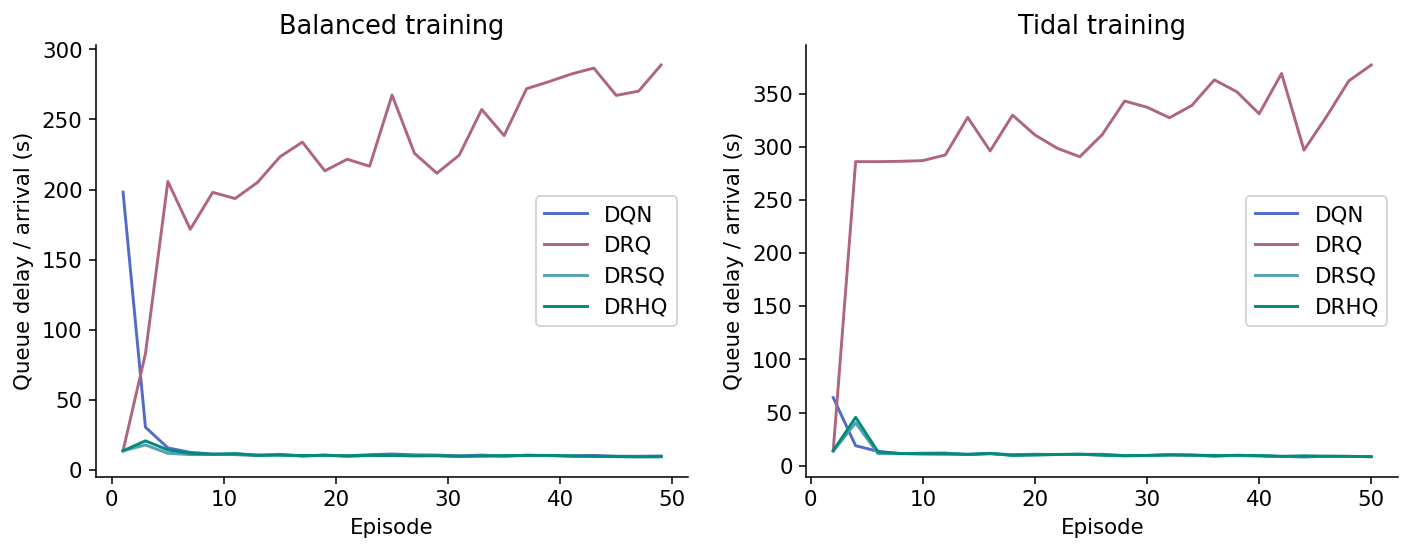

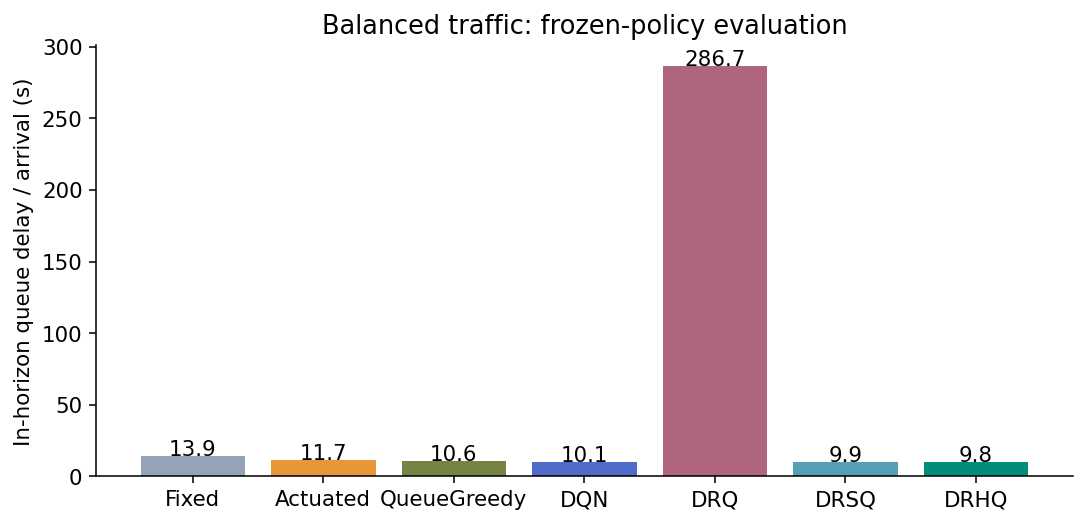

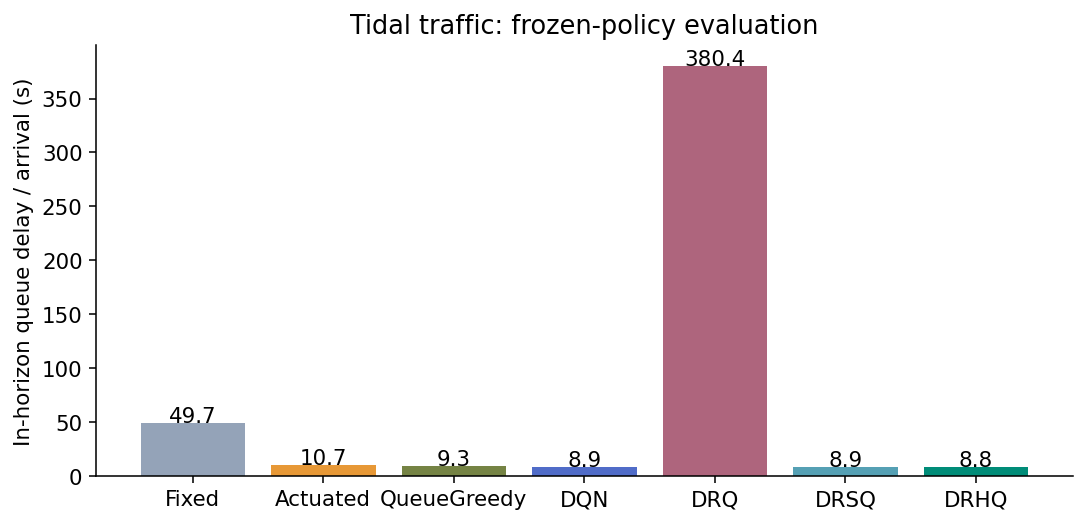

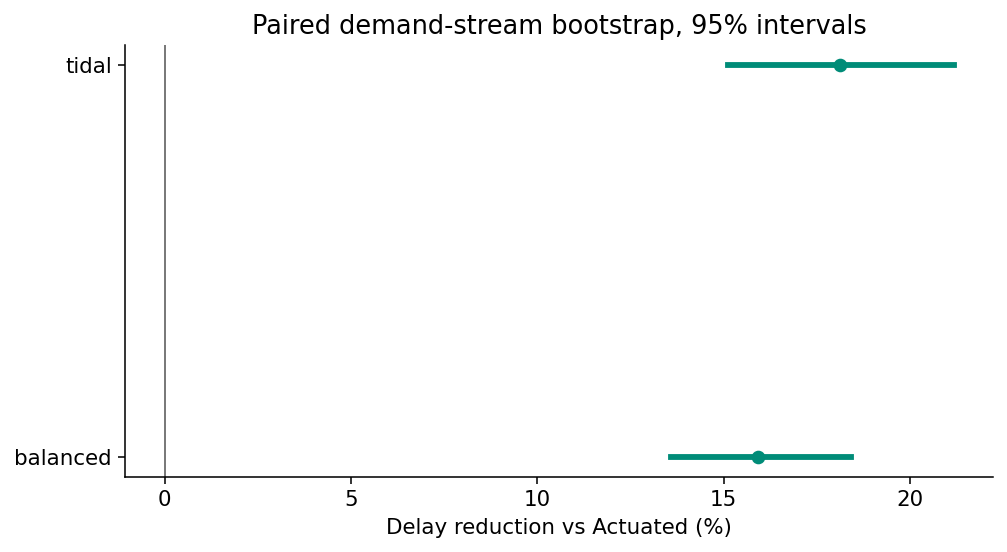

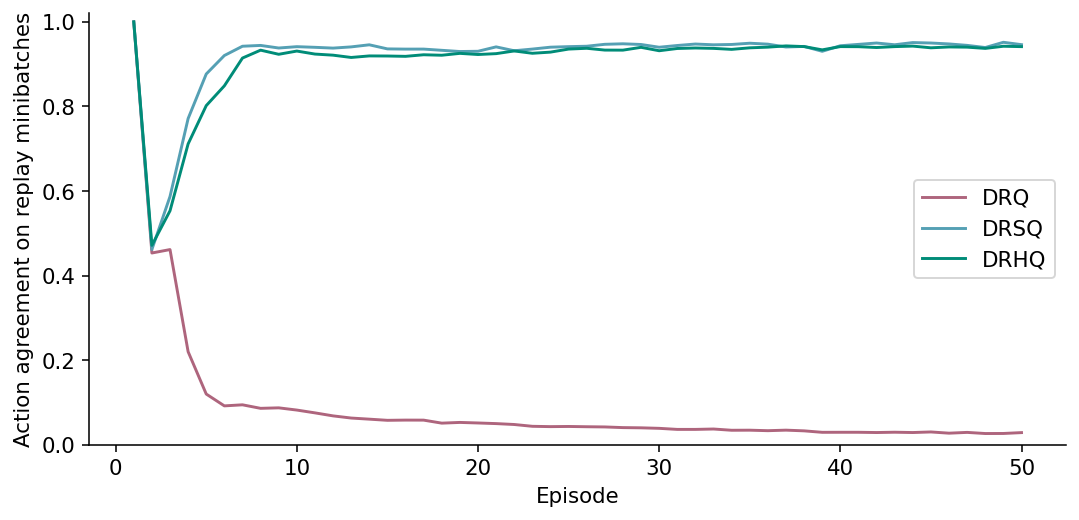

In [16]:
import pandas as pd
import numpy as np
try:
    from IPython.display import display, Image
except ImportError:
    def display(value):
        print(value)
    def Image(filename):
        return f"Figure saved: {filename}"
display(summary.round(3))
evaluation = pd.read_csv('results/evaluation.csv')
display(evaluation.groupby(['scenario','algorithm'])[
    ['throughput_fraction','pending','completed_mean_wait_s','completed_p95_wait_s']].mean().round(3))
display(pd.read_csv('results/training_seed_summary.csv').round(3))
for name in ('learning', 'delay_balanced', 'delay_tidal', 'paired_interval', 'agreement'):
    display(Image(filename=f'results/figures/{name}.png'))


## 11. Example 1: balanced demand

Use the first training seed, rather than choosing the best model. At t=300 seconds inspect the raw sensor features and the contribution of each feature to both scores. The selected action must be the largest score, and all contribution terms must add to that score.

       queued  approaching  total_wait  mean_wait  queue_per_lane  speed
North     6.0          2.0        53.0      8.833             6.0   12.0
South    11.0          0.0       128.0     11.636            11.0    0.0
East      4.0          0.0        12.0      3.000             4.0    0.0
West      0.0          1.0         0.0      0.000             0.0   12.0
               queued  approaching  total_wait  ...  queue_per_lane   speed   score
North / South  3.6409       0.2128      0.2947  ...          3.6409  0.8129  9.0347
East / West    1.2713       0.6455      0.0387  ...          1.2713  0.5263  3.7800

[2 rows x 7 columns]
Chosen action: North / South at 300 seconds
Figure saved: results/figures/queues_balanced.png
Figure saved: results/figures/explain_1.png


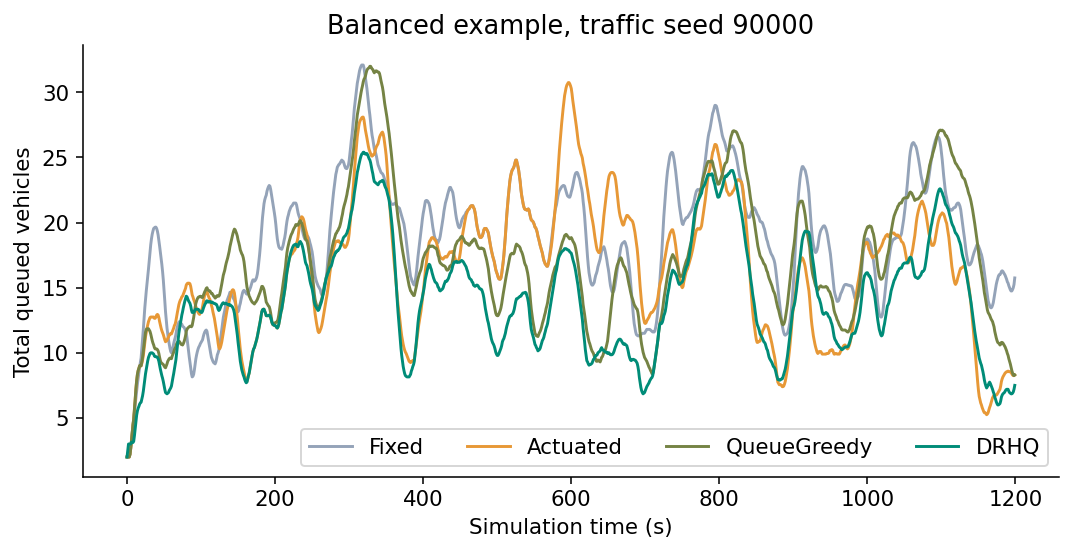

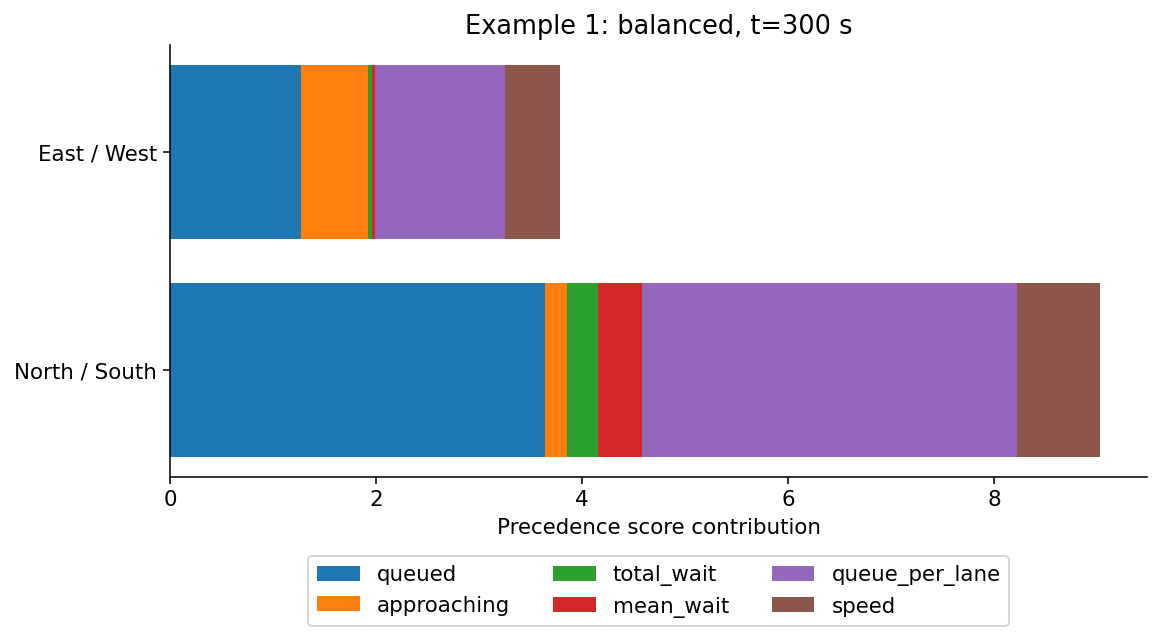

In [17]:
from traffic_control.config import ACTION_NAMES, DIRECTIONS, FEATURE_NAMES
examples = json.loads(Path('results/examples.json').read_text())
def explain_example(example):
    display(pd.DataFrame(example['raw_features'],index=DIRECTIONS,columns=FEATURE_NAMES).round(3))
    terms = np.asarray(example['contributions']).sum(axis=1)
    contributions = pd.DataFrame(terms,index=ACTION_NAMES,columns=FEATURE_NAMES)
    contributions['score'] = example['scores']
    display(contributions.round(4))
    np.testing.assert_allclose(terms.sum(axis=1),example['scores'])
    print('Chosen action:', ACTION_NAMES[example['action']], 'at', example['second'], 'seconds')
explain_example(examples[0])
display(Image(filename='results/figures/queues_balanced.png'))
display(Image(filename='results/figures/explain_1.png'))


## 12. Example 2: demand reversal

Tidal traffic reverses its dominant axis at 600 seconds. At t=900 seconds inspect the demand response and executed queues. The animation samples the recorded trace rather than a separate decorative simulation.

       queued  approaching  total_wait  mean_wait  queue_per_lane  speed
North     0.0          0.0         0.0      0.000             0.0    0.0
South     3.0          0.0        29.0      9.667             3.0    0.0
East      5.0          0.0        47.0      9.400             5.0    0.0
West     10.0          1.0        73.0      7.300            10.0   12.0
               queued  approaching  total_wait  ...  queue_per_lane   speed    score
North / South  0.5952       0.0000      0.0404  ...          0.5952  0.0000   1.3496
East / West    5.3972       0.6455      0.4191  ...          5.3972  0.5263  12.5728

[2 rows x 7 columns]
Chosen action: East / West at 900 seconds
Figure saved: results/figures/queues_tidal.png
Figure saved: results/figures/explain_2.png
Figure saved: results/figures/phase_trace.png
Figure saved: results/figures/tidal_queues.gif


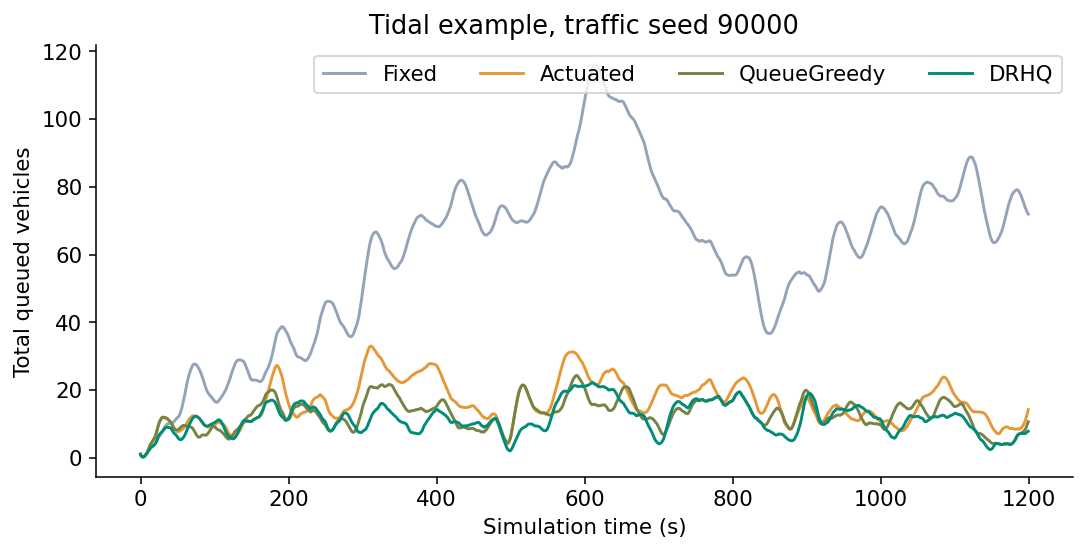

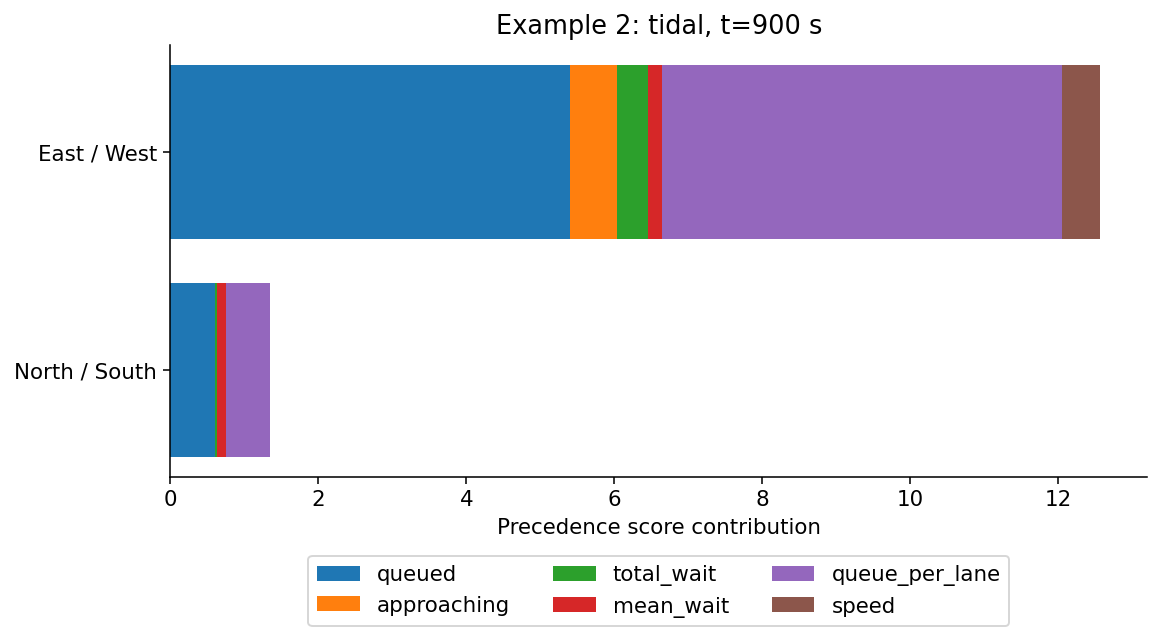

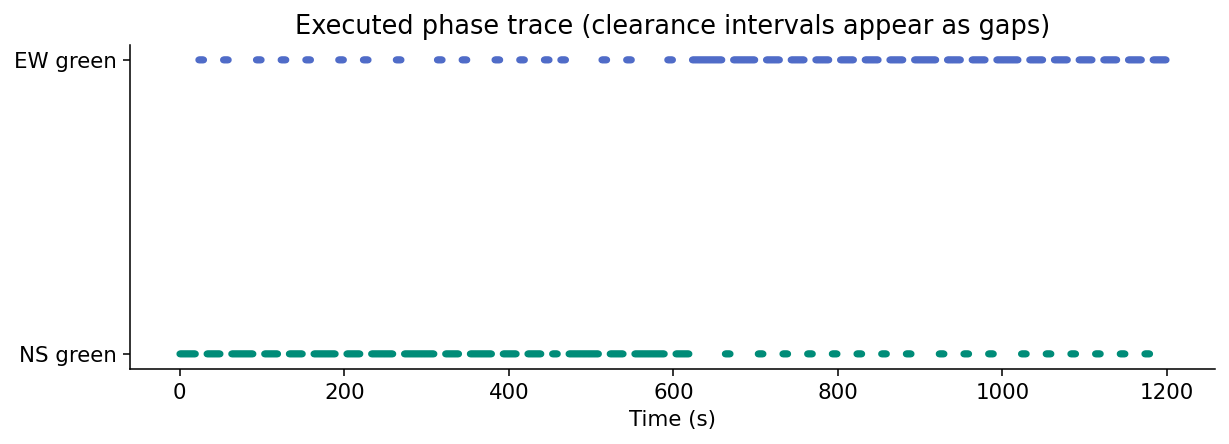

In [18]:
explain_example(examples[1])
display(Image(filename='results/figures/queues_tidal.png'))
display(Image(filename='results/figures/explain_2.png'))
display(Image(filename='results/figures/phase_trace.png'))
from traffic_control.visuals import make_animation
animation_file = make_animation('results')
display(Image(filename=str(animation_file)))


## 13. Monotonicity and complete evidence checks

The analytic derivative check tests continuous traffic features conditional on a fixed clearance category. It does not claim global safety or guarantee fairness. Both examples are independently reconstructed from their contribution terms. Summaries are recomputed from raw rollouts.

In [19]:
display(json.loads(Path('results/monotonicity.json').read_text()))
from validate_results import validate
validate('results')
manifest = json.loads(Path('results/manifest.json').read_text())
print('Training episodes:',manifest['training_episodes_total'])
print('Frozen evaluation rollouts:',manifest['evaluation_rollouts'])
print('Demand seeds:',manifest['evaluation_seeds'])
print('Experiment settings:')
print(json.dumps(manifest['settings'],indent=2))
from traffic_control.proof import save_proof
CONTRIBUTOR_NAME = ''  # Fill with your own name after reviewing and doing the work.
ACTUAL_CONTRIBUTION = ''  # Describe the files/cells you verified and can explain.
diagnostics, proof_checks, contributor_record = save_proof(
    'results', CONTRIBUTOR_NAME, ACTUAL_CONTRIBUTION)
display(diagnostics[['case', 'algorithm', 'delay_per_arrival_s', 'pending', 'conservation_ok']].round(3))
print('Complete proof summary:')
print(json.dumps(proof_checks, indent=2))
print('Contributor record:', contributor_record['status'])
ppt_values = {'summary': summary.to_dict('records'), 'examples': examples,
              'checks': proof_checks, 'monotonicity': json.loads(Path('results/monotonicity.json').read_text())}
Path('results/ppt_values.json').write_text(json.dumps(ppt_values, indent=2))
print('PPT values saved: results/ppt_values.json')


{'11': {'checked_derivatives': 2400, 'sign_violations': 0, 'finite': True}, '22': {'checked_derivatives': 2400, 'sign_violations': 0, 'finite': True}, '33': {'checked_derivatives': 2400, 'sign_violations': 0, 'finite': True}}
Validated 300 frozen rollouts, summaries, example scores and model checkpoints.
Training episodes: 600
Frozen evaluation rollouts: 300
Demand seeds: [90000, 90001, 90002, 90003, 90004, 90005, 90006, 90007, 90008, 90009]
Experiment settings:
{
  "horizon": 1200,
  "decision_seconds": 10,
  "yellow_seconds": 2,
  "all_red_seconds": 1,
  "service_per_second": 1,
  "episodes": 50,
  "batch_size": 32,
  "replay_capacity": 12000,
  "target_interval": 100,
  "warmup": 128,
  "gamma": 0.95,
  "learning_rate": 0.001,
  "policy_learning_rate": 0.003,
  "epsilon_start": 0.3,
  "epsilon_end": 0.03,
  "policy_updates": 2,
  "hidden": 32
}
               case    algorithm  delay_per_arrival_s  pending  conservation_ok
0             empty        Fixed                0.000       

## 14. Arithmetic check for the paper's Figure 2

The old slides attributed 22.53 to W-Left alone. The figure's table gives contributions whose **combined westbound configuration** totals 22.53. The eastbound configuration totals 19.31. This cell checks the addition, not a rerun of the authors' optimizer.

In [20]:
west_through = 0.0 + 2.1 + 0.0 + 0.33
west_left = 3.64 + 0.77 + 4.65 + 11.04
east_through = 1.25 + 0.0 + 0.73 + 0.0
east_left = 5.32 + 1.67 + 10.34 + 0.0
print('Westbound combined:',round(west_through + west_left,2))
print('Eastbound combined:',round(east_through + east_left,2))
assert np.isclose(west_through + west_left,22.53)
assert np.isclose(east_through + east_left,19.31)

# A small arithmetic example, separate from the measured traffic experiment.
from traffic_control.training import td_targets
from traffic_control.networks import softmax
toy_target = td_targets(np.array([-0.4]), np.array([0.]), np.array([[-2., -3.]]), 0.95)[0]
terminal_target = td_targets(np.array([-0.4]), np.array([1.]), np.array([[-2., -3.]]), 0.95)[0]
actor_probabilities = softmax(np.array([[0.5, 1.5]]))[0]
hardmax_loss = -np.log(actor_probabilities[1])
assert np.isclose(toy_target, -2.3) and np.isclose(terminal_target, -0.4)
print('Teaching example TD target:', toy_target, 'terminal target:', terminal_target)
print('G softmax:', actor_probabilities.round(4), 'DRHQ cross-entropy:', round(hardmax_loss, 4))


Westbound combined: 22.53
Eastbound combined: 19.31
Teaching example TD target: -2.3 terminal target: -0.4
G softmax: [0.2689 0.7311] DRHQ cross-entropy: 0.3133


## 15. Contributor proof and recording

Complete your own run and keep the executed notebook. Budhdi and Sumeet should each record actual work and explain their part. A proposed split is environment/training/balanced example and evaluation/limitations/tidal example. This is a plan until completed, not a statement of past contribution.

The supplied assignment requires the actual video Drive link on the last slide, both PPT and video under 10 MB, and video length at most seven minutes. The revised deadline in the professor's email is October 11, 2026. Use the graphical 22-slide deck and speaker notes, record from the timed seven-minute script in slideshow mode, and inspect the encoded result before fresh portal submission.

Known limits: synthetic one-lane through traffic, idealized sensing, two phase groups, compressed observations, in-horizon delay, no physical spillback or turning, no SUMO reproduction, and only three training seeds. PPO/CMA-ES are reviewed but not implemented here.

## 16. Download your evidence

This ZIP contains your current code, raw CSVs, frozen models, tests, plots and manifest. Save the executed notebook separately using File > Download > Download .ipynb.

In [21]:
import zipfile
# Confirm the raw evidence still matches the manifest before downloading.
validate('results')
zip_path = WORKDIR.parent / 'DRL_Group87_Colab_Evidence.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as archive:
    for relative in ('traffic_control','tests','results'):
        for file in Path(relative).rglob('*'):
            if file.is_file() and '__pycache__' not in file.parts:
                archive.write(file,str(file))
    for relative in ('run_experiments.py','validate_results.py'):
        archive.write(relative,relative)
print('Evidence ZIP:',zip_path, 'bytes:',zip_path.stat().st_size)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Outside Colab: open the ZIP from the printed path.')


Validated 300 frozen rollouts, summaries, example scores and model checkpoints.
Evidence ZIP: /workspace/scratch/981aa7d81c9f/build/notebook_test_final_v2/DRL_Group87_Colab_Evidence.zip bytes: 1393773
Outside Colab: open the ZIP from the printed path.
